The Source of data here to use besides IPINN is TVD.

In [1]:
import numpy as np
import math 
import seaborn as sns
import matplotlib.pyplot as plt


from tqdm import tqdm
import torch
import torch.nn as nn

In [2]:
Nx = 200
# cfl = 0.2
tmax = 1 # time 0 ~ 1

# viscosity_coeff = (0.01/math.pi)
viscosity_coeff = 0.02

x = np.linspace(-1,1, 200)

# t = 0 , I.C
u = -1 * np.sin(math.pi * x)
dx = abs(x[1] - x[0])

dt = 0.002 # cfl * dx / np.max(np.abs(u))

nt = int(tmax/ dt) # + 1

uf = np.zeros((nt,Nx))
uf[0,:] = u

print(nt)
print(dt)
print(nt * dt, tmax)

500
0.002
1.0 1


In [3]:
def f(u):
    y = 0.5 * u**2
    yp = u
    return y, yp

In [4]:
def minmod(a,b):
    return 0.5 * (np.sign(a)+ np.sign(b)) * np.minimum(np.abs(a), np.abs(b))

In [5]:
def RHS(u, dx, viscosity_coeff):
    #diffusion term
    diffusion_term = viscosity_coeff * (np.roll(u,1)- 2*u + np.roll(u,-1))/ dx**2
    
    ux = minmod((u - np.roll(u,1))/dx ,  (np.roll(u,-1) - u)/dx)
    
    uL = np.roll(u -0.5 * dx*ux,1)
    uR = u -0.5 * dx*ux
    fL,fpL = f(uL)
    fR,fpR = f(uR)
    a = np.maximum(np.abs(fpL), np.abs(fpR))
    
    H =0.5 * (fL + fR - a * (uR - uL))
    
    conv_term  = -(np.roll(H,-1)-H)/dx
    
    y = conv_term + diffusion_term
    return y

In [6]:
for i in range(1, nt):
    u1 = u + dt * RHS(u,dx,viscosity_coeff)
    u = 0.5 * u + 0.5 * (u1 + dt * RHS(u1, dx,viscosity_coeff))
    uf[i, :] = u

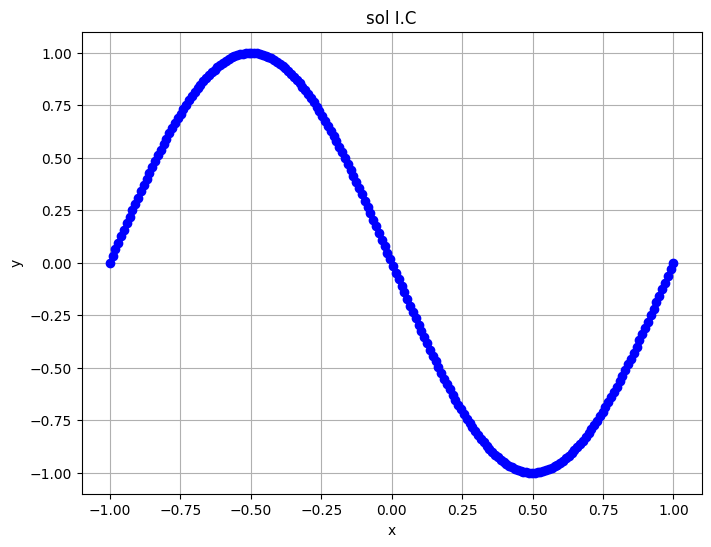

In [7]:
plt.figure(figsize=(8,6))
plt.plot(x, uf[0], '-o', color = 'b')
plt.title("sol I.C")
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True)
plt.show()

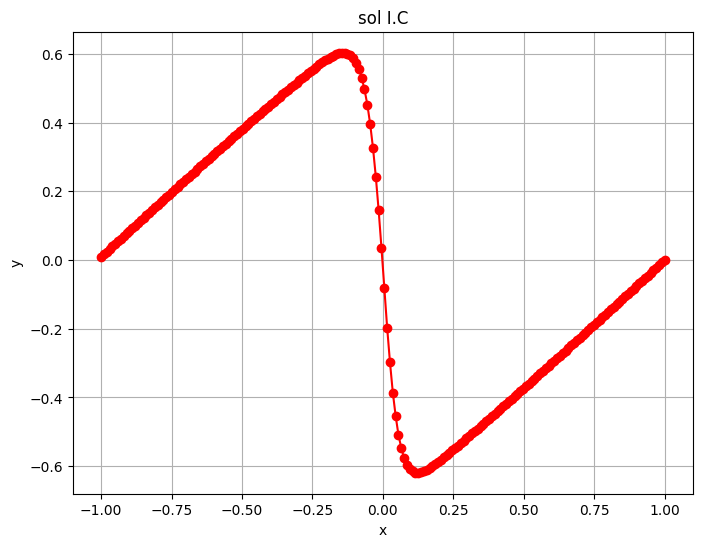

In [8]:
plt.figure(figsize=(8,6))
plt.plot(x, uf[-1], '-o', color = 'r')
plt.title("sol I.C")
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True)
plt.show()

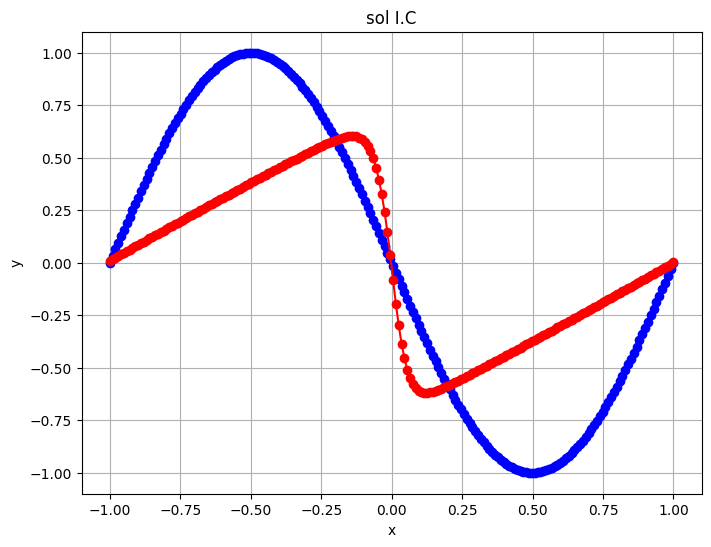

In [9]:
plt.figure(figsize=(8,6))
plt.plot(x, uf[0], '-o', color = 'b')
plt.plot(x, uf[-1], '-o', color = 'r')
plt.title("sol I.C")
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True)
plt.show()

In [10]:
uf

array([[ 1.22464680e-16,  3.15685498e-02,  6.31056313e-02, ...,
        -6.31056313e-02, -3.15685498e-02, -1.22464680e-16],
       [ 5.04816912e-03,  3.39789169e-02,  6.29057353e-02, ...,
        -6.26316775e-02, -3.39141776e-02, -4.99532216e-03],
       [ 8.06837905e-03,  3.55817910e-02,  6.32706630e-02, ...,
        -6.28071191e-02, -3.54144418e-02, -7.93565334e-03],
       ...,
       [ 8.80213458e-03,  1.65360123e-02,  2.42552594e-02, ...,
        -1.44125704e-02, -6.68651117e-03,  1.05285876e-03],
       [ 8.79440206e-03,  1.65166666e-02,  2.42243446e-02, ...,
        -1.43854607e-02, -6.67097320e-03,  1.05678648e-03],
       [ 8.78668460e-03,  1.64973705e-02,  2.41935139e-02, ...,
        -1.43584398e-02, -6.65548965e-03,  1.06069439e-03]])

In [11]:
tf = np.linspace(0,1, nt)

In [12]:
tf

array([0.        , 0.00200401, 0.00400802, 0.00601202, 0.00801603,
       0.01002004, 0.01202405, 0.01402806, 0.01603206, 0.01803607,
       0.02004008, 0.02204409, 0.0240481 , 0.0260521 , 0.02805611,
       0.03006012, 0.03206413, 0.03406814, 0.03607214, 0.03807615,
       0.04008016, 0.04208417, 0.04408818, 0.04609218, 0.04809619,
       0.0501002 , 0.05210421, 0.05410822, 0.05611222, 0.05811623,
       0.06012024, 0.06212425, 0.06412826, 0.06613226, 0.06813627,
       0.07014028, 0.07214429, 0.0741483 , 0.0761523 , 0.07815631,
       0.08016032, 0.08216433, 0.08416834, 0.08617234, 0.08817635,
       0.09018036, 0.09218437, 0.09418838, 0.09619238, 0.09819639,
       0.1002004 , 0.10220441, 0.10420842, 0.10621242, 0.10821643,
       0.11022044, 0.11222445, 0.11422846, 0.11623246, 0.11823647,
       0.12024048, 0.12224449, 0.1242485 , 0.12625251, 0.12825651,
       0.13026052, 0.13226453, 0.13426854, 0.13627255, 0.13827655,
       0.14028056, 0.14228457, 0.14428858, 0.14629259, 0.14829

In [13]:
xf = x

In [14]:
xf

array([-1.        , -0.98994975, -0.9798995 , -0.96984925, -0.95979899,
       -0.94974874, -0.93969849, -0.92964824, -0.91959799, -0.90954774,
       -0.89949749, -0.88944724, -0.87939698, -0.86934673, -0.85929648,
       -0.84924623, -0.83919598, -0.82914573, -0.81909548, -0.80904523,
       -0.79899497, -0.78894472, -0.77889447, -0.76884422, -0.75879397,
       -0.74874372, -0.73869347, -0.72864322, -0.71859296, -0.70854271,
       -0.69849246, -0.68844221, -0.67839196, -0.66834171, -0.65829146,
       -0.64824121, -0.63819095, -0.6281407 , -0.61809045, -0.6080402 ,
       -0.59798995, -0.5879397 , -0.57788945, -0.5678392 , -0.55778894,
       -0.54773869, -0.53768844, -0.52763819, -0.51758794, -0.50753769,
       -0.49748744, -0.48743719, -0.47738693, -0.46733668, -0.45728643,
       -0.44723618, -0.43718593, -0.42713568, -0.41708543, -0.40703518,
       -0.39698492, -0.38693467, -0.37688442, -0.36683417, -0.35678392,
       -0.34673367, -0.33668342, -0.32663317, -0.31658291, -0.30

In [15]:
tf_tensor = torch.tensor(tf)
xf_tensor = torch.tensor(xf)

print(len(tf_tensor))
print(len(xf_tensor))

500
200


In [16]:
tf_tensor

tensor([0.0000, 0.0020, 0.0040, 0.0060, 0.0080, 0.0100, 0.0120, 0.0140, 0.0160,
        0.0180, 0.0200, 0.0220, 0.0240, 0.0261, 0.0281, 0.0301, 0.0321, 0.0341,
        0.0361, 0.0381, 0.0401, 0.0421, 0.0441, 0.0461, 0.0481, 0.0501, 0.0521,
        0.0541, 0.0561, 0.0581, 0.0601, 0.0621, 0.0641, 0.0661, 0.0681, 0.0701,
        0.0721, 0.0741, 0.0762, 0.0782, 0.0802, 0.0822, 0.0842, 0.0862, 0.0882,
        0.0902, 0.0922, 0.0942, 0.0962, 0.0982, 0.1002, 0.1022, 0.1042, 0.1062,
        0.1082, 0.1102, 0.1122, 0.1142, 0.1162, 0.1182, 0.1202, 0.1222, 0.1242,
        0.1263, 0.1283, 0.1303, 0.1323, 0.1343, 0.1363, 0.1383, 0.1403, 0.1423,
        0.1443, 0.1463, 0.1483, 0.1503, 0.1523, 0.1543, 0.1563, 0.1583, 0.1603,
        0.1623, 0.1643, 0.1663, 0.1683, 0.1703, 0.1723, 0.1743, 0.1764, 0.1784,
        0.1804, 0.1824, 0.1844, 0.1864, 0.1884, 0.1904, 0.1924, 0.1944, 0.1964,
        0.1984, 0.2004, 0.2024, 0.2044, 0.2064, 0.2084, 0.2104, 0.2124, 0.2144,
        0.2164, 0.2184, 0.2204, 0.2224, 

In [17]:
xf_tensor

tensor([-1.0000, -0.9899, -0.9799, -0.9698, -0.9598, -0.9497, -0.9397, -0.9296,
        -0.9196, -0.9095, -0.8995, -0.8894, -0.8794, -0.8693, -0.8593, -0.8492,
        -0.8392, -0.8291, -0.8191, -0.8090, -0.7990, -0.7889, -0.7789, -0.7688,
        -0.7588, -0.7487, -0.7387, -0.7286, -0.7186, -0.7085, -0.6985, -0.6884,
        -0.6784, -0.6683, -0.6583, -0.6482, -0.6382, -0.6281, -0.6181, -0.6080,
        -0.5980, -0.5879, -0.5779, -0.5678, -0.5578, -0.5477, -0.5377, -0.5276,
        -0.5176, -0.5075, -0.4975, -0.4874, -0.4774, -0.4673, -0.4573, -0.4472,
        -0.4372, -0.4271, -0.4171, -0.4070, -0.3970, -0.3869, -0.3769, -0.3668,
        -0.3568, -0.3467, -0.3367, -0.3266, -0.3166, -0.3065, -0.2965, -0.2864,
        -0.2764, -0.2663, -0.2563, -0.2462, -0.2362, -0.2261, -0.2161, -0.2060,
        -0.1960, -0.1859, -0.1759, -0.1658, -0.1558, -0.1457, -0.1357, -0.1256,
        -0.1156, -0.1055, -0.0955, -0.0854, -0.0754, -0.0653, -0.0553, -0.0452,
        -0.0352, -0.0251, -0.0151, -0.00

In [18]:
combined_tensor_x_train = torch.empty((len(tf)*len(xf), 2), dtype=torch.float32)

In [19]:
combined_tensor_x_train

tensor([[0., 0.],
        [0., 0.],
        [0., 0.],
        ...,
        [0., 0.],
        [0., 0.],
        [0., 0.]])

In [20]:
# DATA creation

index = 0
for i in range(len(tf)):
    for j in range(len(xf)):
        combined_tensor_x_train[index][0] = xf_tensor[j]
        combined_tensor_x_train[index][1] = tf_tensor[i]
        index = index + 1

In [21]:
len(combined_tensor_x_train)

100000

In [22]:
combined_tensor_x_train

tensor([[-1.0000,  0.0000],
        [-0.9899,  0.0000],
        [-0.9799,  0.0000],
        ...,
        [ 0.9799,  1.0000],
        [ 0.9899,  1.0000],
        [ 1.0000,  1.0000]])

In [23]:
your_tensor = torch.tensor(uf, dtype= torch.float32)

In [24]:
your_tensor

tensor([[ 1.2246e-16,  3.1569e-02,  6.3106e-02,  ..., -6.3106e-02,
         -3.1569e-02, -1.2246e-16],
        [ 5.0482e-03,  3.3979e-02,  6.2906e-02,  ..., -6.2632e-02,
         -3.3914e-02, -4.9953e-03],
        [ 8.0684e-03,  3.5582e-02,  6.3271e-02,  ..., -6.2807e-02,
         -3.5414e-02, -7.9357e-03],
        ...,
        [ 8.8021e-03,  1.6536e-02,  2.4255e-02,  ..., -1.4413e-02,
         -6.6865e-03,  1.0529e-03],
        [ 8.7944e-03,  1.6517e-02,  2.4224e-02,  ..., -1.4385e-02,
         -6.6710e-03,  1.0568e-03],
        [ 8.7867e-03,  1.6497e-02,  2.4194e-02,  ..., -1.4358e-02,
         -6.6555e-03,  1.0607e-03]])

In [25]:
flattened_tensor_y_train = your_tensor.view(-1)

In [26]:
flattened_tensor_y_train

tensor([ 1.2246e-16,  3.1569e-02,  6.3106e-02,  ..., -1.4358e-02,
        -6.6555e-03,  1.0607e-03])

In [27]:
flattened_tensor_y_train.shape

torch.Size([100000])

In [28]:
flattened_tensor_y_train = flattened_tensor_y_train.unsqueeze(1)

In [29]:
flattened_tensor_y_train

tensor([[ 1.2246e-16],
        [ 3.1569e-02],
        [ 6.3106e-02],
        ...,
        [-1.4358e-02],
        [-6.6555e-03],
        [ 1.0607e-03]])

In [30]:
flattened_tensor_y_train.shape

torch.Size([100000, 1])

In [31]:
lambda_value = 2.0
print("the real value =", viscosity_coeff, " our Inverse-PINNs value", lambda_value)

the real value = 0.02  our Inverse-PINNs value 2.0


In [32]:
class NN(nn.Module):
    def __init__(self):
        super(NN, self).__init__()
        self.net = torch.nn.Sequential(
            nn.Linear(2,20),
            nn.Tanh(),
            nn.Linear(20,30),
            nn.Tanh(),
            nn.Linear(30,20),
            nn.Tanh(),
            nn.Linear(20,20),
            nn.Tanh(),
            nn.Linear(20,1),
            nn.Tanh(),
        )
    def forward(self, x):
        out = self.net(x)
        return out

In [33]:
class Net:
    def __init__(self):
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

        self.lambda_value = torch.tensor([lambda_value], requires_grad=True).float().to(device)

        self.lambda_value = nn.Parameter(self.lambda_value)

        self.model = NN().to(device)

        self.model.register_parameter("lambda_value", self.lambda_value)

        self.h = 0.1
        self.k = 0.1
        #mesh
        x = torch.arange(-1, 1+self.h, self.h)
        t = torch.arange(0, 1+self.k, self.k)

        self.X = torch.stack(torch.meshgrid(x,t)).reshape(2,-1).T

        ## input the data ##
        self.X_train = combined_tensor_x_train
        self.y_train = flattened_tensor_y_train
        ####

        self.X = self.X.to(device)
        self.X.requires_grad = True

        self.X_train = self.X_train.to(device)
        self.y_train = self.y_train.to(device)

        self.adam = torch.optim.Adam(self.model.parameters())

        self.criterion = torch.nn.MSELoss()

        self.iter = 1

    def loss_func(self):
        self.adam.zero_grad()

        #####
        y_pred = self.model(self.X_train)
        loss_data = self.criterion(y_pred, self.y_train)
        ######

        u = self.model(self.X)

        du_dX = torch.autograd.grad(
            u, 
            self.X,
            grad_outputs= torch.ones_like(u),
            create_graph=True,
            retain_graph=True,
        )[0]

        du_dt = du_dX[:,1]
        du_dx = du_dX[:,0]

        du_dXX = torch.autograd.grad(
            du_dX,
            self.X,
            grad_outputs= torch.ones_like(du_dX),
            create_graph=True,
            retain_graph=True
        )[0]

        du_dxx = du_dXX[:,0]

        lambda_pde = self.lambda_value

        loss_pde = self.criterion(du_dt + 1 * u.squeeze()*du_dx, lambda_pde * du_dxx)

        loss = loss_pde + loss_data
        loss.backward()

        if self.iter % 100 == 0:
            print("iteration number = ",self.iter, "  loss value =", loss.item(), 
                  " real mu = ", viscosity_coeff, "  IPINN lambda = ", self.lambda_value.item())

        self.iter = self.iter + 1

        return loss

    def train(self):
        self.model.train()

        for i in range(5000):
            self.adam.step(self.loss_func)

    def eval_(self):
        self.model.eval()

In [34]:
net = Net()
net.train()
net.model.eval()

d:\PythonEnvs\tf_gpu\lib\site-packages\torch\functional.py:534: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\native\TensorShape.cpp:3596.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


iteration number =  100   loss value = 0.19271986186504364  real mu =  0.02   IPINN lambda =  1.9173027276992798
iteration number =  200   loss value = 0.17568156123161316  real mu =  0.02   IPINN lambda =  1.8536003828048706
iteration number =  300   loss value = 0.16333651542663574  real mu =  0.02   IPINN lambda =  1.7696998119354248
iteration number =  400   loss value = 0.1580583155155182  real mu =  0.02   IPINN lambda =  1.6607834100723267
iteration number =  500   loss value = 0.15528617799282074  real mu =  0.02   IPINN lambda =  1.5354993343353271
iteration number =  600   loss value = 0.152568519115448  real mu =  0.02   IPINN lambda =  1.4055886268615723
iteration number =  700   loss value = 0.14981211721897125  real mu =  0.02   IPINN lambda =  1.2692196369171143
iteration number =  800   loss value = 0.1464826613664627  real mu =  0.02   IPINN lambda =  1.1226049661636353
iteration number =  900   loss value = 0.14200647175312042  real mu =  0.02   IPINN lambda =  0.9623

NN(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=20, bias=True)
    (1): Tanh()
    (2): Linear(in_features=20, out_features=30, bias=True)
    (3): Tanh()
    (4): Linear(in_features=30, out_features=20, bias=True)
    (5): Tanh()
    (6): Linear(in_features=20, out_features=20, bias=True)
    (7): Tanh()
    (8): Linear(in_features=20, out_features=1, bias=True)
    (9): Tanh()
  )
)

In [35]:
h = 0.01
k = 0.01

x = torch.arange(-1,1,h)
t = torch.arange(0,1,k)

X= torch.stack(torch.meshgrid(x,t)).reshape(2,-1).T
X= X.to(net.X.device)

model = net.model
model.eval()
with torch.no_grad():
    y_pred = model(X)
    y_pred = y_pred.reshape(len(x),len(t)).cpu().numpy()

In [36]:
y_pred_inverse = y_pred

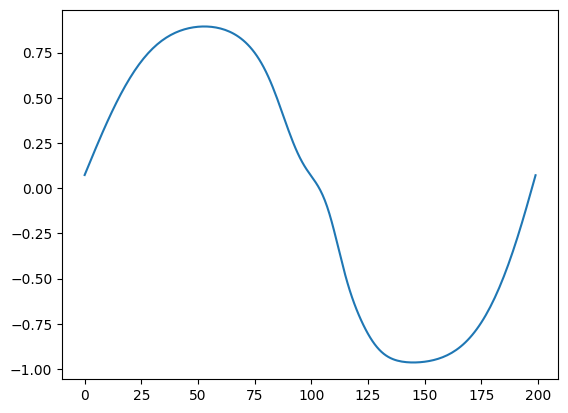

In [37]:
plt.plot(y_pred_inverse[:,0])

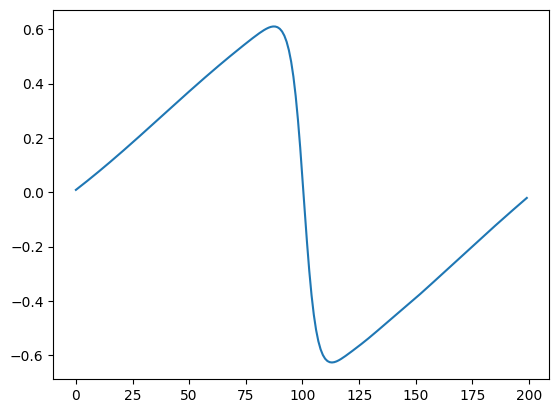

In [38]:
plt.plot(y_pred_inverse[:,-1])

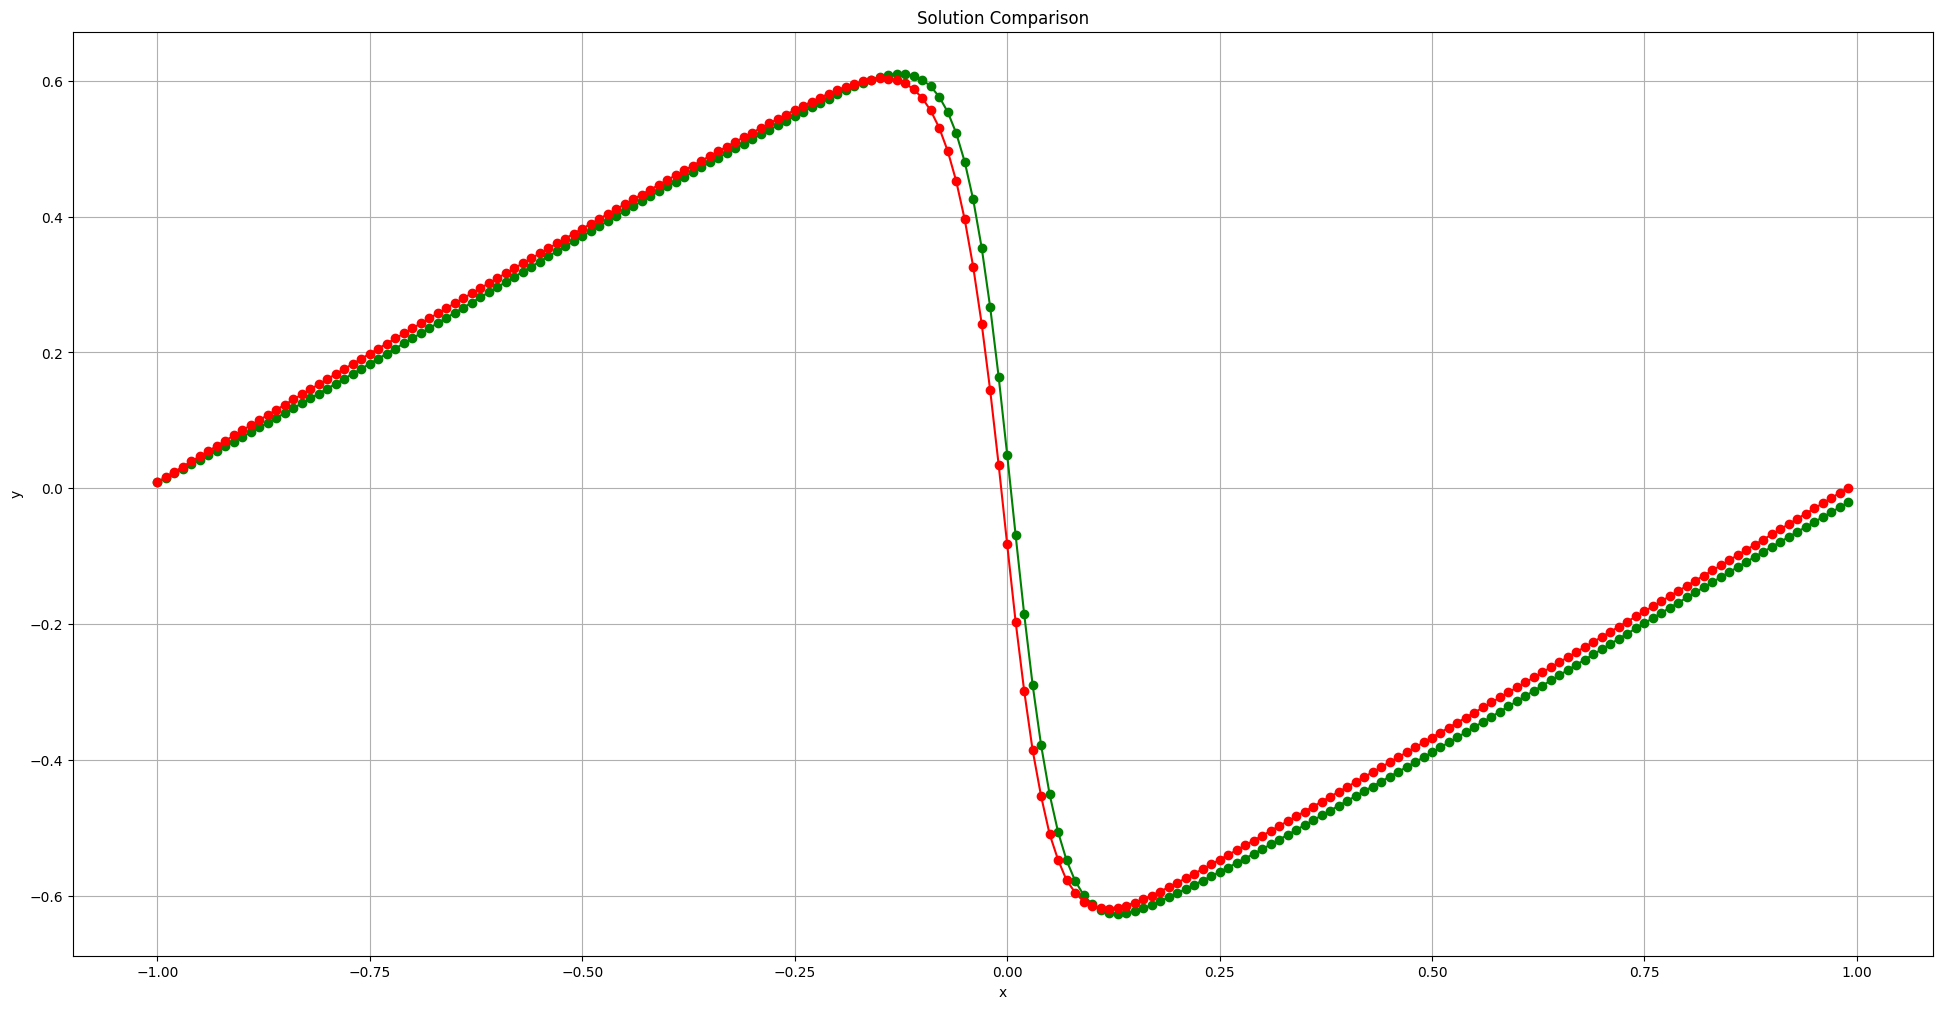

In [39]:
plt.figure(figsize=(24,12))
plt.plot(x, y_pred_inverse[:,-1], '-o', color = 'g') # IPINNs
plt.plot(x, uf[-1], '-o', color= 'r') #TVD
plt.title('Solution Comparison')
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True)
plt.show()

In [40]:
sns.set_style("white")
plt.figure(figsize=(5,3), dpi=3000)
sns.heatmap(y_pred_inverse, cmap='jet')

<Axes: >

Comapring with PINNs

In [41]:
class NN(nn.Module):
    def __init__(self):
        super(NN, self).__init__()
        self.net = torch.nn.Sequential(
            nn.Linear(2,20),
            nn.Tanh(),
            nn.Linear(20,30),
            nn.Tanh(),
            nn.Linear(30,30),
            nn.Tanh(),
            nn.Linear(30,20),
            nn.Tanh(),
            nn.Linear(20,20),
            nn.Tanh(),
            nn.Linear(20,1)
        )

    def forward(self, x):
        out = self.net(x)
        return out

In [ ]:
class Net:
    def __init__(self):
        device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

        self.model = NN().to(device)
        # computation domain
        self.h = 0.1
        self.k = 0.1
        x = torch.arange(-1, 1+self.h, self.h)
        t = torch.arange(0, 1+self.k, self.k)

        self.X = torch.stack(torch.meshgrid(x,t)).reshape(2,-1).T

        # train data
        bc1 = torch.stack(torch.meshgrid(x[0],t)).reshape(2,-1).T
        bc2 = torch.stack(torch.meshgrid(x[-1],t)).reshape(2,-1).T
        ic = torch.stack(torch.meshgrid(x,t[0])).reshape(2,-1).T
        self.X_train = torch.cat([bc1, bc2, ic])

        y_bc1 = torch.zeros(len(bc1))
        y_bc2 = torch.zeros(len(bc2))
        y_ic = -torch.sin(math.pi * ic[:,0])
        self.y_train = torch.cat([y_bc1, y_bc2, y_ic])
        self.y_train = self.y_train.unsqueeze(1)

        self.X = self.X.to(device)
        self.y_train = self.y_train.to(device)
        self.X_train = self.X_train.to(device)
        self.X.requires_grad = True

        # optimizer setting
        self.adam = torch.optim.Adam(self.model.parameters())

        # tweaking adam optimizer for short memories (l-bfgs)
        self.optimizer = torch.optim.LBFGS(
            self.model.parameters(),
            lr=1.0,
            max_iter = 500000,
            max_eval = 500000,
            history_size = 50,
            tolerance_grad= 1e-7,
            tolerance_change=1.0 * np.finfo(float).eps,
            line_search_fn = "strong_wolfe"
        )

        self.criterion = torch.nn.MSELoss()
        self.iter = 1
        
    def loss_func(self):
        self.adam.zero_grad()
        self.optimizer.zero_grad()

        y_pred = self.model(self.X_train)
        loss_data = self.criterion(y_pred, self.y_train)

        u = self.model(self.X)

        du_dX = torch.autograd.grad(
            u,
            self.X,
            grad_outputs = torch.ones_like(u),
            create_graph = True,
            retain_graph = True
            )[0]

        # print(du_dX)
        # print("xxxxxxxxxxxxxxxxxxx")
        # print(du_dX[0])

        du_dt = du_dX[:,1]
        du_dx = du_dX[:,0]

        du_dXX = torch.autograd.grad(
            du_dX,
            self.X,
            grad_outputs = torch.ones_like(du_dX),
            create_graph = True,
            retain_graph = True
            )[0]

        du_dxx = du_dXX[:,0]

        # loss_pde = self.criterion(du_dt + u.squeeze()*du_dx , (0.01/math.pi) * du_dxx)
        loss_pde = self.criterion(du_dt + 1* u.squeeze()*du_dx , (0.02) * du_dxx)
        loss = loss_pde + loss_data
        loss.backward()

        if self.iter % 100 == 0:
            print(self.iter, loss.item())
        self.iter = self.iter + 1
        
        return loss

    def train(self):
        self.model.train()
        for i in range (1000):
            self.adam.step(self.loss_func)
        self.optimizer.step(self.loss_func)

    def eval_(self):
        self.model.eval()

In [43]:
# training PINNs 
net = Net()
net.train()
net.model.eval()

100 0.14923322200775146
200 0.05720526725053787
300 0.024686742573976517
400 0.016084950417280197
500 0.011361337266862392
600 0.008761628530919552
700 0.007322212681174278
800 0.006194364745169878
900 0.00519940722733736
1000 0.004326901864260435
1100 0.0009938428411260247
1200 0.00044061680091544986
1300 0.00021299553918652236
1400 0.00012328170123510063
1500 8.46482435008511e-05
1600 6.658510392298922e-05
1700 5.364605749491602e-05
1800 4.633190110325813e-05
1900 3.9649225072935224e-05
2000 3.45411644957494e-05
2100 2.8651993488892913e-05
2200 2.3460328520741314e-05
2300 2.0088820747332647e-05
2400 1.683309892541729e-05
2500 1.4774888768442906e-05
2600 1.291079206566792e-05
2700 1.1697417903633323e-05
2800 1.074602550943382e-05
2900 9.824496373767033e-06
3000 8.551724022254348e-06
3100 7.755362275929656e-06
3200 6.533484338433482e-06
3300 5.6819949350028764e-06
3400 5.252078153716866e-06
3500 4.603275556291919e-06
3600 4.266599717084318e-06
3700 3.9759615901857615e-06
3800 3.5647540

NN(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=20, bias=True)
    (1): Tanh()
    (2): Linear(in_features=20, out_features=30, bias=True)
    (3): Tanh()
    (4): Linear(in_features=30, out_features=30, bias=True)
    (5): Tanh()
    (6): Linear(in_features=30, out_features=20, bias=True)
    (7): Tanh()
    (8): Linear(in_features=20, out_features=20, bias=True)
    (9): Tanh()
    (10): Linear(in_features=20, out_features=1, bias=True)
  )
)

In [44]:
h = 0.01
k = 0.01

x = torch.arange(-1,1,h)
t = torch.arange(0,1,k)

X= torch.stack(torch.meshgrid(x,t)).reshape(2,-1).T
X= X.to(net.X.device)

model = net.model
model.eval()
with torch.no_grad():
    y_pred = model(X)
    y_pred = y_pred.reshape(len(x),len(t)).cpu().numpy()

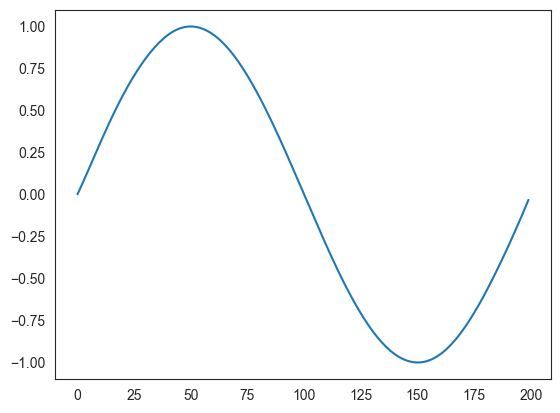

In [45]:
plt.plot(y_pred[:,0])

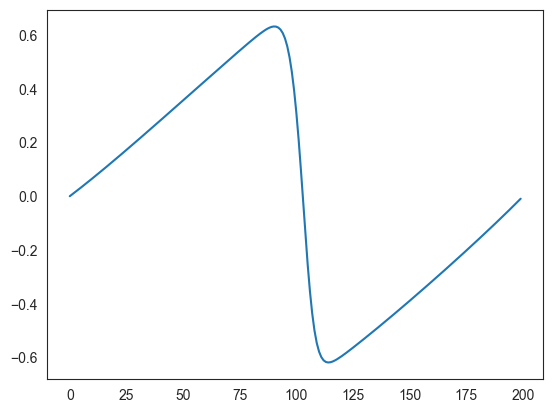

In [46]:
plt.plot(y_pred[:,-1])

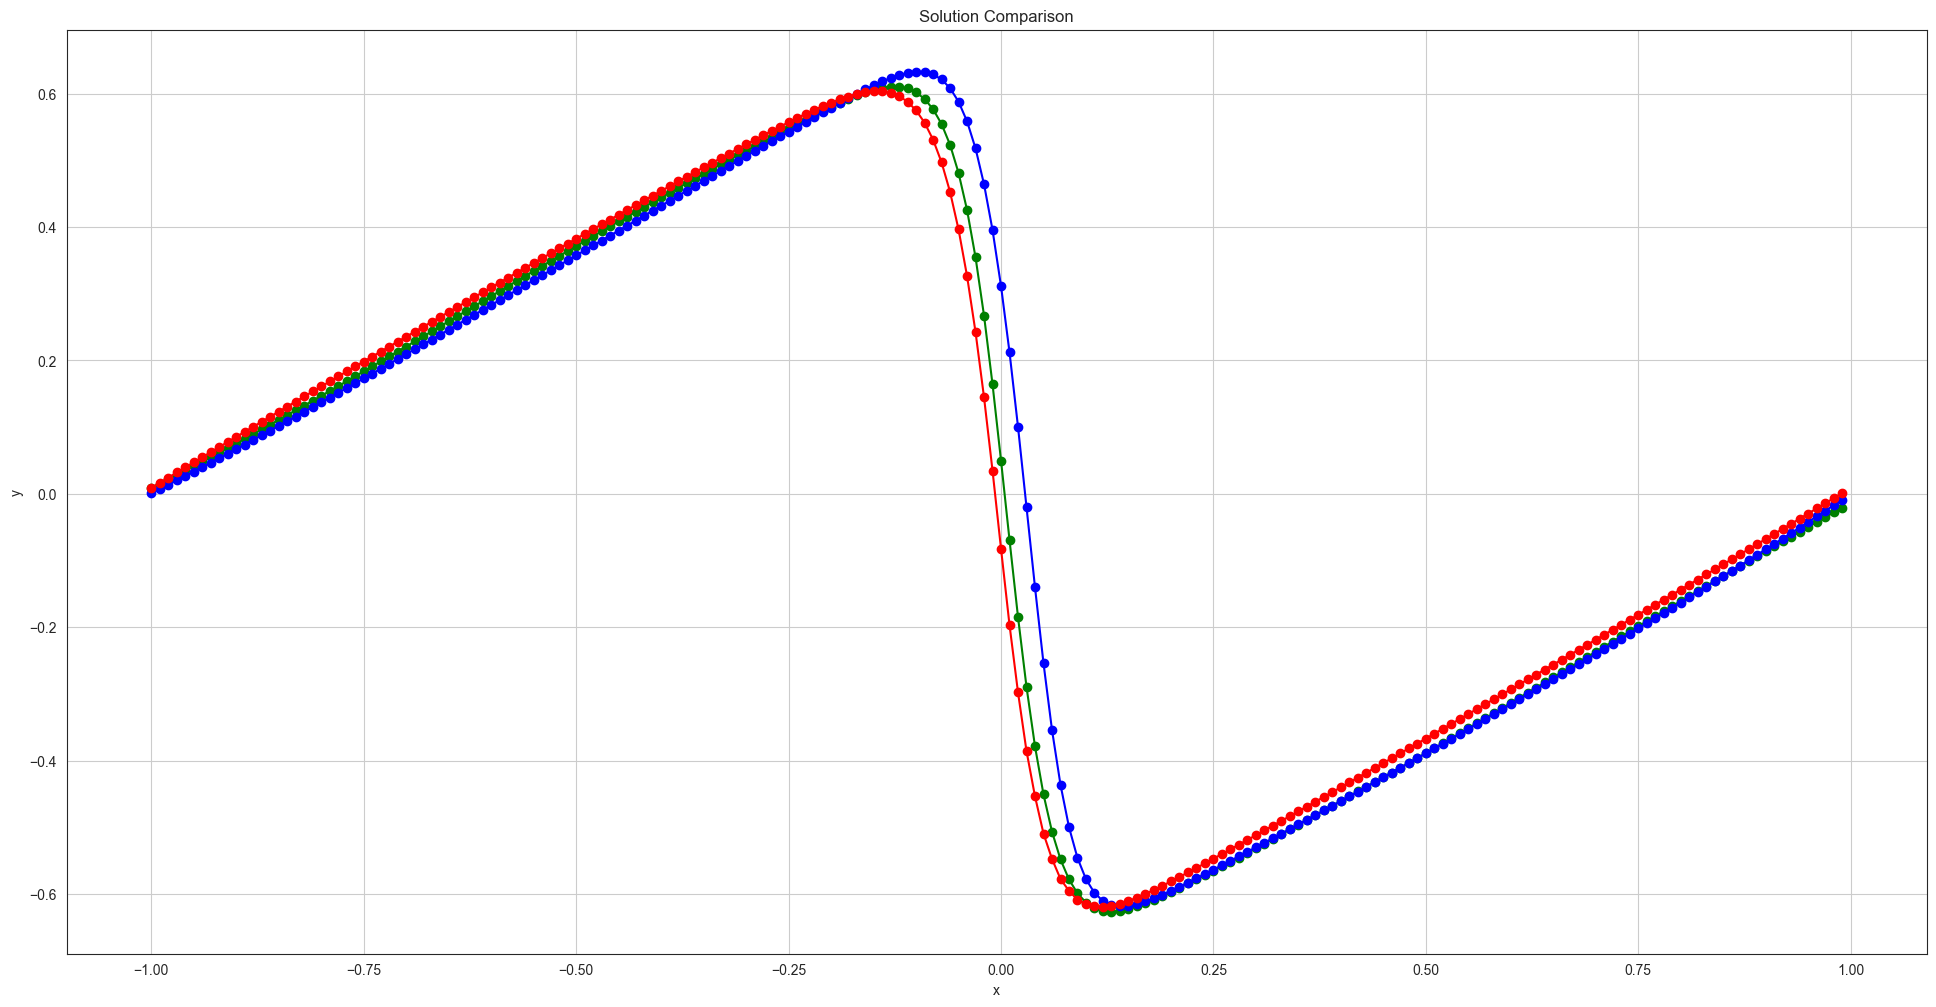

In [47]:
plt.figure(figsize=(24,12))
plt.plot(x, y_pred_inverse[:,-1], '-o', color = 'g') # IPINNs
plt.plot(x, y_pred[:,-1], '-o', color= 'b') #PINNs
plt.plot(x, uf[-1], '-o', color= 'r') #TVD
plt.title('Solution Comparison')
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True)
plt.show()